In [2]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils, base

In [2]:
# ns=200
# nd=300
# n = 10
# rng = jax.random.PRNGKey(12345)

# beta= 5.75911 # non-int params3
# b = 2.55
# bk = 4.0

ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta= 5.85277 # params3
b = 2.55
bk = 4.0

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_wLens_record(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [3]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [ ]:
wlens_array = my_driver.steady_record.flatten()
# np.save("../data/fixed_params/wLens_distribution/int_variableN_min1_params3.npy", wlens_array)
# np.save("../tmp_data/int_params3.npy", wlens_array)

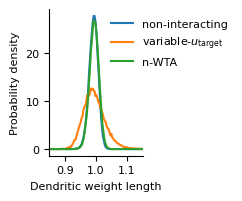

In [ ]:
plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

wlens_array_nonInt = np.load("../data/fixed_params/wLens_distribution/nonInt_params3.npy")
w_lens_array_int_variable_n_min1 = np.load("../data/fixed_params/wLens_distribution/int_variableN_min1_params3.npy")
wlens_array_int = np.load("../data/fixed_params/wLens_distribution/int_params3.npy")

xmin = 0.85
xmax = 1.15

bins = 100
range_ = (xmin, xmax)

def hist_midpoints(data, bins, range_):
    counts, edges = np.histogram(data, bins=bins, range=range_, density=True)
    mids = 0.5 * (edges[:-1] + edges[1:])
    return mids, counts

fig, ax = plt.subplots(figsize=(2.3, 1.9), constrained_layout=True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for data, label in [
    (wlens_array_nonInt, "non-interacting"),
    (w_lens_array_int_variable_n_min1, r'variable-$u_{\text{target}}$'),
    (wlens_array_int, "n-WTA"),
]:
    mids, counts = hist_midpoints(data, bins, range_)
    ax.plot(mids, counts, label=label)

ax.set_xlabel("Dendritic weight length");
ax.set_ylabel("Probability density");
ax.set_xlim(xmin, xmax)
ax.legend(bbox_to_anchor=(0.55, 1), loc='upper left', frameon=False);
# ax.legend()

plt.savefig("../figures/fig2/wLen_distribution_params3.pdf", bbox_inches="tight")
# plt.savefig("../figures/wLen_distribution_params3.png")

In [ ]:
np.mean(wlens_array_nonInt), np.mean(w_lens_array_int_variable_n), np.mean(wlens_array_int)

(np.float32(0.9924255), np.float32(0.9948845), np.float32(0.99182653))

: 